In [2]:
import numpy as np
import pickle
import os
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.interpolate import interp1d
homedir = os.path.expanduser("~")

In [5]:
spec_nobroad_all = []
wl = np.loadtxt(f"{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/high-resolution/wavelength_micron.txt")
for t in range(20):
    spec_nobroad = np.loadtxt(f"{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/high-resolution/spectrum_erg.s.cm3_nobroaden_time{t+1}.txt")
    spec_nobroad_all.append(spec_nobroad)
spec_nobroad_all = np.array(spec_nobroad_all)
spec_nobroad_mean = np.nanmedian(spec_nobroad_all,axis=0)
spec_nobroad_all.shape

(20, 460654)

L band

In [13]:
# in um
wlmin = 3.0
wlmax = 3.3
wlstep = 0.05*1e-4

print('wl(angstrom):', wlmin*1e4, wlmax*1e4)
print('step(angstrom):', wlstep*1e4)

wl(angstrom): 30000.0 33000.0
step(angstrom): 0.05


In [14]:
wl_lin = np.arange(wlmin, wlmax+wlstep, wlstep, dtype=np.float32)  # Include endpoint
interp_func = interp1d(wl, spec_nobroad_mean, kind='linear', bounds_error=False, fill_value=0.0)
spec_nobroad_lin = interp_func(wl_lin)
spec_nobroad_lin.shape

(60001,)

In [15]:
# save daospec input spec to fits
hdu = fits.PrimaryHDU(spec_nobroad_lin.astype(np.float32))

# WCS header keywords
hdu.header['CRPIX1'] = 1              # Reference pixel
hdu.header['CRVAL1'] = wlmin*1e4          # Wavelength at reference pixel
hdu.header['CDELT1'] = wlstep*1e4          # Step size
hdu.header['CTYPE1'] = 'LINEAR'

# Write to FITS
hdu.writeto(f'{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/w1049b_gcm_L_nobroad_lin.fits', overwrite=True)

M band

In [50]:
# in um
wlmin = 4.4
wlmax = 4.95
wlstep = 1*1e-4

print('wl(angstrom):', wlmin*1e4, wlmax*1e4)
print('step(angstrom):', wlstep*1e4)

wl(angstrom): 44000.0 49500.0
step(angstrom): 1.0


In [51]:
wl_lin = np.arange(wlmin, wlmax+wlstep, wlstep, dtype=np.float32)  # Include endpoint
interp_func = interp1d(wl, spec_nobroad_mean, kind='linear', bounds_error=False, fill_value='extrapolate')
spec_nobroad_lin = interp_func(wl_lin)
spec_nobroad_lin.shape

(5501,)

In [52]:
# save daospec input spec to fits
hdu = fits.PrimaryHDU(spec_nobroad_lin.astype(np.float32))

# WCS header keywords
hdu.header['CRPIX1'] = 1              # Reference pixel
hdu.header['CRVAL1'] = wlmin*1e4          # Wavelength at reference pixel
hdu.header['CDELT1'] = wlstep*1e4          # Step size
hdu.header['CTYPE1'] = 'LINEAR'

# Write to FITS
hdu.writeto(f'{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/w1049b_gcm_M_nobroad_lin.fits', overwrite=True)

In [53]:
check_data = fits.getdata(f'{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/w1049b_gcm_L_nobroad_lin.fits')
check_header = fits.getheader(f'{homedir}/uoedrive/data/gcm_hires/w1049b-sept2025/w1049b_gcm_L_nobroad_lin.fits')
print(check_header)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    1 / number of array dimensions                     NAXIS1  =                60001                                                  EXTEND  =                    T                                                  CRPIX1  =                    1                                                  CRVAL1  =              30000.0                                                  CDELT1  =                 0.05                                                  CTYPE1  = 'LINEAR  '                                                            END                                                                                                                                                                                                                                                                                     

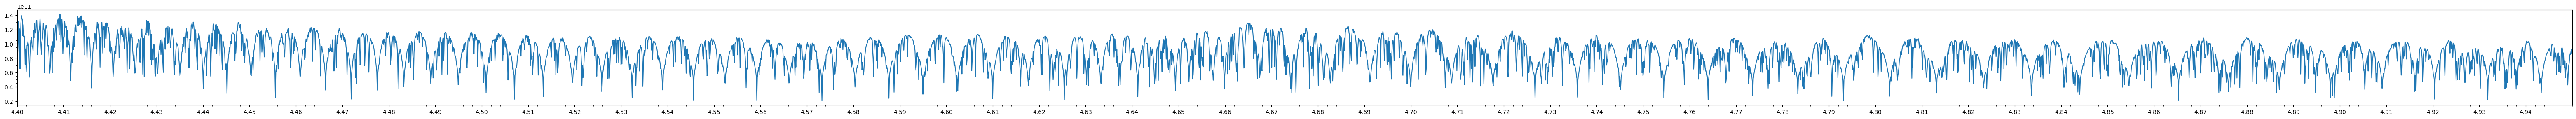

In [54]:
plt.figure(figsize=(80,3))
plt.plot(wl_lin, spec_nobroad_lin)
plt.xlim(wlmin, wlmax)
plt.xticks(np.arange(wlmin, wlmax, 0.01))
plt.minorticks_on();